<a href="https://colab.research.google.com/github/MariaVrett/Linear-Regression/blob/main/Linear_Regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Import Libriaries

In [66]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import accuracy_score
from sklearn.metrics import mean_squared_error, mean_absolute_error
from sklearn.preprocessing import StandardScaler

# Load Dataset

In [67]:
df = pd.read_csv('diabetes.csv')
df

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1
...,...,...,...,...,...,...,...,...,...
763,10,101,76,48,180,32.9,0.171,63,0
764,2,122,70,27,0,36.8,0.340,27,0
765,5,121,72,23,112,26.2,0.245,30,0
766,1,126,60,0,0,30.1,0.349,47,1


# Convert DataFrame to Numpy arrays

In [68]:
selected_features = ['Pregnancies', 'BloodPressure', 'BMI', 'Age']
input_df = df[selected_features]
targets_df = df['Glucose']

x = input_df.to_numpy()
y = targets_df.to_numpy()
x.shape, y.shape


((768, 4), (768,))

# Split Dataset to Train-Test

In [69]:
seed = 0
test_size = 0.30

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=test_size, random_state=seed)
x_train.shape, y_train.shape, x_test.shape, y_test.shape

((537, 4), (537,), (231, 4), (231,))

# Create a Linear Regression Model

In [70]:
model = LinearRegression()

# Train Model on Training Set

In [71]:
model.fit(x_train, y_train)

LinearRegression()

# Evaluate Model on Test Set

In [72]:
y_pred = model.predict(x_test)

mse = mean_squared_error(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)

print(f'Mean Squared Error (MSE): {round(mse, 2)}')
print(f'Mean Absolute Error (MAE): {round(mae, 2)}')

print("Mean Absolute Error is easier to interpret, as it shows the average error in the same unit of measurement as Glucose.")
print("In medical applications, a very large error is much more dangerous than many small errors.")
print("Mean Squared Error (MSE) is considered more appropriate here, because it strictly penalizes large errors by squaring them.")

Mean Squared Error (MSE): 929.89
Mean Absolute Error (MAE): 23.6
Mean Absolute Error is easier to interpret, as it shows the average error in the same unit of measurement as Glucose.
In medical applications, a very large error is much more dangerous than many small errors.
Mean Squared Error (MSE) is considered more appropriate here, because it strictly penalizes large errors by squaring them.


# Feature Importance

Retrain the model using standard scaling. Then, investigate coefficients. Larger coefficient values  →  more important features

# Data Normalization

In [73]:
scaler = StandardScaler()
scaler.fit(x_train)

x_train_scaled = scaler.transform(x_train)
x_test_scaled = scaler.transform(x_test)

# Model Training Evaluation

The MSE of the scaled model is: 929.89


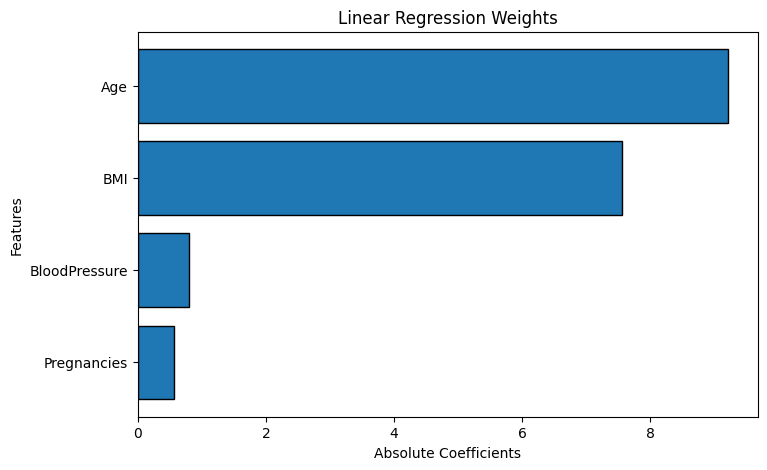

After using StanadardScaler and normalizing the data, we can see from the graph that Age and BMI are the most important factors


In [74]:
model.fit(x_train_scaled, y_train)

y_pred_scaled = model.predict(x_test_scaled)
mse_scaled = mean_squared_error(y_test, y_pred_scaled)

print(f'The MSE of the scaled model is: {round(mse_scaled, 2)}')

coeffs = model.coef_
importance_weights = np.abs(coeffs)

plt.figure(figsize=(8, 5))
plt.barh(input_df.columns, importance_weights, edgecolor='black')
plt.title('Linear Regression Weights')
plt.xlabel('Absolute Coefficients')
plt.ylabel('Features')
plt.grid(False)
plt.show()

print("After using StanadardScaler and normalizing the data, we can see from the graph that Age and BMI are the most important factors")